## San Diego VMT Study

# Import Libraries

In [187]:
import numpy as np # Core numerical and array operations
import pandas as pd # Data table and analysis operations
import matplotlib.pyplot as plt # Plotting; syntax and appearance similar to Matlab
import pathlib # file handling robust to switching between Mac, PC, and Linux platforms
import geopandas as gpd # GIS functionality added to pandas. We will use lightly here to make a map.

# VMT Data Import

In [188]:
cwd = pathlib.Path().cwd()
cwd


PosixPath('/Users/dvg/Documents/USF/Fall 2026/Urban Energy/git/The858')

In [189]:
inputdir = cwd / 'inputdata' # pathlib abstracts the Mac vs. PC syntax difference using '/' not as a string
inputdir

PosixPath('/Users/dvg/Documents/USF/Fall 2026/Urban Energy/git/The858/inputdata')

In [190]:
datafile = inputdir / 'CARB-UCB-CA_VMT_Estimates_DataVintage_Oct2025_PRELIMINARY_FOR_STUDENT_USE.csv'


# View Data

In [191]:
data = pd.read_csv(datafile)
data.head(10)


,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,60259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0000,5.040,5.040,6.370,5.040,5.040,3.273
1,3,60250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0000,5.155,5.155,6.486,5.155,5.155,3.388
2,4,60250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0000,5.185,5.185,6.515,5.185,5.185,3.418
3,5,60250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0000,5.185,5.185,6.516,5.185,5.185,3.418
4,6,60730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0000,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384
5,7,60373104003,-0.115,-0.090,-6.003,-0.839,-2.742,-0.0708,0.0,2.4049,-7.456,-7.456,-6.125,-9.861,-9.861,-3.887
6,8,60310007014,0.124,0.362,0.172,-0.354,0.567,-0.0103,0.0,0.0000,0.860,0.860,2.191,0.860,0.860,-0.968
7,9,60310003002,0.132,0.362,0.889,0.000,0.711,-0.1259,0.0,0.0000,1.968,1.968,3.298,1.968,1.968,0.140
8,10,60310002002,0.133,0.362,3.701,0.000,0.699,0.4480,0.0,0.0000,5.343,5.343,6.674,5.343,5.343,3.515
9,11,60590865023,0.133,0.362,-3.051,-0.542,-3.067,-0.4123,0.0,2.4049,-4.172,-4.172,-2.841,-6.577,-6.577,-0.603


# Clean GEOID Column

In [192]:
data['GEOID'] = data['GEOID'].map(str).str.zfill(12)
data.head()

,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,060259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0,5.040,5.040,6.370,5.040,5.040,3.273
1,3,060250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0,5.155,5.155,6.486,5.155,5.155,3.388
2,4,060250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0,5.185,5.185,6.515,5.185,5.185,3.418
3,5,060250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0,5.185,5.185,6.516,5.185,5.185,3.418
4,6,060730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384


In [193]:
data_cleaned = data.set_index('GEOID')[['VMT_diff_state']]
data_cleaned.head()

,VMT_diff_state
GEOID,
060259400003,6.370
060250108002,6.486
060250108001,6.515
060250111003,6.516
060730100132,-2.346


In [194]:
data_cleaned.describe()

,VMT_diff_state
count,23190.000000
mean,-0.256459
std,4.770563
min,-14.135000
25%,-2.704750
50%,0.303000
75%,2.936000
max,10.676000


# Calculate State-wide VMT Baseline using EMFAC (LDA, LDT1, LDT2, MCY)

In [195]:
VMT_state = 716/39.5 # sum of VMT from downloaded spreadsheet divided by California population

In [196]:
vmt = data_cleaned + VMT_state # important distinction between EMFAC (VMT_state), which is VMT driven within the boundaries of the state 
# and neighborhood data which are miles driven by residents of the state (data_clearned)

vmt = vmt.rename({'VMT_diff_state': 'VMTpc'}, axis=1)
vmt.describe()

,VMTpc
count,23190.000000
mean,17.870123
std,4.770563
min,3.991582
25%,15.421832
50%,18.429582
75%,21.062582
max,28.802582


# Visualization

In [197]:
ca_cbg_shapefile_path = inputdir / 'cb_2019_06_bg_500k' / 'cb_2019_06_bg_500k.shp'
gdf = gpd.read_file(ca_cbg_shapefile_path) # Basic geopandas read; it will figure out it is a shapefile format.
gdf.head() # dataframe functions are inherited by geodataframes, in addition to geodataframe specific functions. 

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry
0,06,037,800408,1,1500000US060378004081,060378004081,1,BG,2792751,1500447,"POLYGON ((-118.78754 34.02718, -118.78607 34.0..."
1,06,041,124200,4,1500000US060411242004,060411242004,4,BG,2259455,973726,"POLYGON ((-122.48698 37.89918, -122.48416 37.9..."
2,06,059,062619,4,1500000US060590626194,060590626194,4,BG,369794,343273,"POLYGON ((-117.77753 33.53639, -117.77558 33.5..."
3,06,051,000101,1,1500000US060510001011,060510001011,1,BG,2978150540,1148631,"POLYGON ((-118.94597 37.77522, -118.94348 37.7..."
4,06,093,000200,1,1500000US060930002001,060930002001,1,BG,1300052761,72751421,"POLYGON ((-122.25174 41.75805, -122.24754 41.7..."


<Axes: >

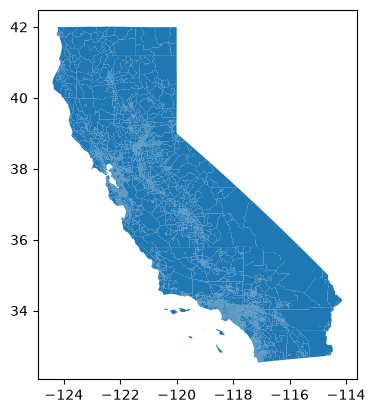

In [198]:
gdf.plot()

In [199]:
gdf['ALAND'].sum() / 1e6 # convert m^2 to km^2

np.float64(403660.088482)

# Extract San Diego Data

In [200]:
sd_shape = gdf[gdf['COUNTYFP'] == '073']
len(gdf)

23196

<Axes: >

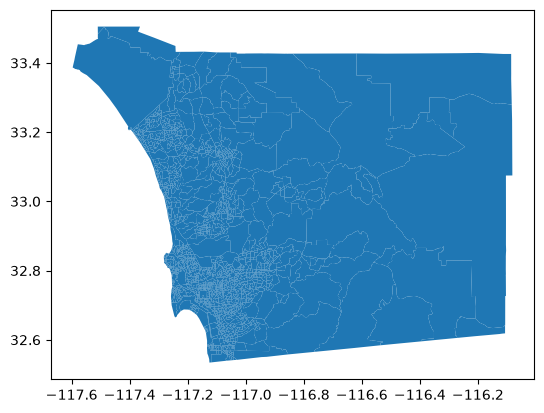

In [201]:
sd_shape.plot()

# Merge

In [202]:
merged = sd_shape.merge(vmt, left_on='GEOID', right_index=True, how='inner')
len(merged)

1794

In [203]:
merged.head()

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry,VMTpc
27,06,073,003305,1,1500000US060730033051,060730033051,1,BG,441435,0,"POLYGON ((-117.09519 32.70412, -117.09492 32.7...",15.308582
36,06,073,008347,2,1500000US060730083472,060730083472,2,BG,408199,0,"POLYGON ((-117.15141 32.92595, -117.15186 32.9...",17.900582
39,06,073,008006,3,1500000US060730080063,060730080063,3,BG,109500,0,"POLYGON ((-117.26217 32.80799, -117.25928 32.8...",17.273582
85,06,073,015801,1,1500000US060730158011,060730158011,1,BG,430195,0,"POLYGON ((-116.96235 32.79911, -116.9581 32.79...",15.260582
94,06,073,011601,2,1500000US060730116012,060730116012,2,BG,222974,0,"POLYGON ((-117.10356 32.6672, -117.09535 32.66...",14.350582


In [204]:
sd_vmt = merged.set_index('GEOID')[['VMTpc', 'geometry']]
sd_vmt.head()

,VMTpc,geometry
GEOID,,
060730033051,15.308582,"POLYGON ((-117.09519 32.70412, -117.09492 32.7..."
060730083472,17.900582,"POLYGON ((-117.15141 32.92595, -117.15186 32.9..."
060730080063,17.273582,"POLYGON ((-117.26217 32.80799, -117.25928 32.8..."
060730158011,15.260582,"POLYGON ((-116.96235 32.79911, -116.9581 32.79..."
060730116012,14.350582,"POLYGON ((-117.10356 32.6672, -117.09535 32.66..."


# Map

<Axes: >

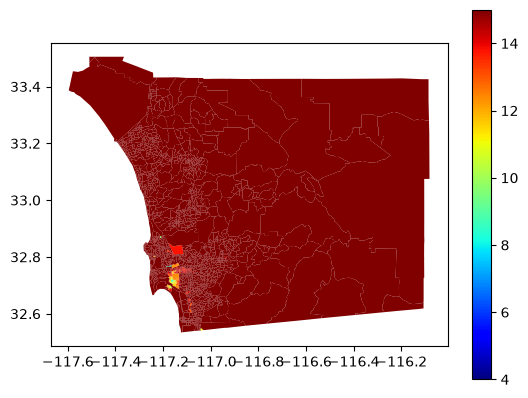

In [205]:
sd_vmt.plot(column='VMTpc', legend=True, cmap='jet', vmin=4, vmax=15)


# Merge with ACS population and housing Data

In [206]:
ca_pop_data_file = inputdir / 'ACSDT5Y2019.B01003_2026-09-27T122429' / 'ACSDT5Y2019.B01003-Data.csv'
ca_pop_data = pd.read_csv(ca_pop_data_file)
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Total,Margin of Error!!Total,NaN
1,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN
2,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN
3,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN
4,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN


In [207]:
ca_pop_data = pd.read_csv(ca_pop_data_file, skiprows=[1])
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN
1,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN
2,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN
3,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN
4,1500000US060014003002,"Block Group 2, Census Tract 4003, Alameda Coun...",1237,263,NaN


Trim Geoid 15000000US Prefix

In [208]:
ca_pop_data['GEOID'] = ca_pop_data['GEO_ID'].map(lambda x: x[9:]) # remove first nine characters
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4,GEOID
0,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN,060014001001
1,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN,060014002001
2,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN,060014002002
3,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN,060014003001
4,1500000US060014003002,"Block Group 2, Census Tract 4003, Alameda Coun...",1237,263,NaN,060014003002


Set GEOID as Index, rename column of interest, and drop remainder

In [209]:
pop = ca_pop_data.set_index('GEOID')[['B01003_001E']].rename({'B01003_001E': 'Population'}, axis=1)
pop.head()

,Population
GEOID,
060014001001,3120
060014002001,990
060014002002,1017
060014003001,1134
060014003002,1237


Function to combine Housing + Population Data 

In [210]:
def read_census_table(table_name, filename, variable_name,
                      skiprows=[1], inputdir=inputdir, geo_in_name='GEO_ID', geo_out_name='GEOID', trim_length=9,
                      column_suffix='_001E'):

    # Read data
    data = pd.read_csv(inputdir / filename, skiprows=skiprows)

    # Trim leading FIPS code strings.
    data[geo_out_name] = data[geo_in_name].map(lambda x: x[trim_length:])

    # Set index, rename column to something more readable, and drop other columns.
    column_name = table_name + column_suffix # Using '+' for a string concatenates.
    data_out = data.set_index(geo_out_name)[[column_name]].rename({column_name: variable_name}, axis=1)
    
    return data_out

In [211]:
read_census_table('B01003', 'ACSDT5Y2019.B01003_2026-09-27T122429/ACSDT5Y2019.B01003-Data.csv', 'Population').sum()

Population    39283497
dtype: int64

In [212]:
housing_units = read_census_table('B25001', 'ACSDT5Y2019.B25001_2026-09-27T131118/ACSDT5Y2019.B25001-Data.csv', 'Housing Units')
housing_units.head()

,Housing Units
GEOID,
060014001001,1354
060014002001,435
060014002002,425
060014003001,449
060014003002,758


In [213]:
housing_units.sum()

Housing Units    14175976
dtype: int64

Merge VMT, Population, Housing Units

In [214]:
vmt_merged = vmt.merge(pop, left_index=True, right_index=True, how='inner')
vmt_merged = vmt_merged.merge(housing_units, left_index=True, right_index=True, how='inner')
vmt_merged.head()

,VMTpc,Population,Housing Units
GEOID,,,
060259400003,24.496582,382,485
060250108002,24.612582,809,332
060250108001,24.641582,319,158
060250111003,24.642582,2010,669
060730100132,15.780582,3148,879


In [215]:
len(vmt_merged)

23190

# Statistics

In [216]:
statewide_mean_vmt_calc = (vmt_merged['VMTpc'] * vmt_merged['Population']).sum() / vmt_merged['Population'].sum()
statewide_mean_vmt_calc


np.float64(18.135571996504336)

In [217]:
statewide_mean_vmt_calc - VMT_state

np.float64(0.008989718023322268)

Histogram

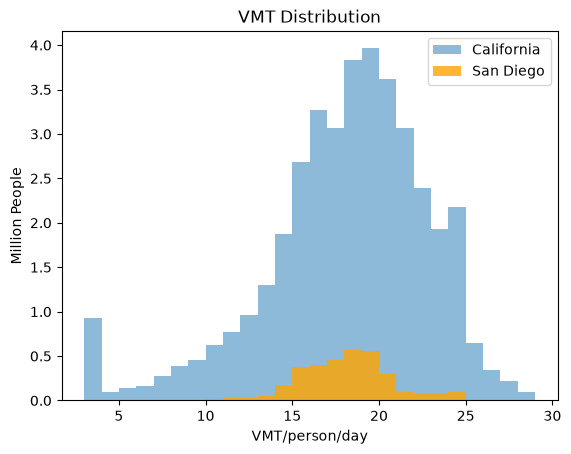

In [218]:
# Plot the statewide data
plt.hist(vmt_merged['VMTpc'], weights=vmt_merged['Population'] / 1e6, bins=np.arange(3, 30), alpha=0.5, label='California')
# Set bins to be 1 VMT from 3 to 30, use millions of people for plotting convenience.

# Filter San Diego County (state FIPS 06, county FIPS 073)
sd_vmt_merged = vmt_merged[vmt_merged.index.str.startswith('06073')]
plt.hist(sd_vmt_merged['VMTpc'], weights=sd_vmt_merged['Population'] / 1e6, bins=np.arange(3, 30), color='orange', alpha=0.8, label='San Diego')

plt.xlabel('VMT/person/day')
plt.ylabel('Million People')
plt.title('VMT Distribution')
plt.legend()



In [219]:
vmt_merged = vmt_merged.merge(gdf[['GEOID', 'ALAND']], left_index=True, right_on='GEOID', how='inner')
vmt_merged = vmt_merged.set_index('GEOID')
vmt_merged.head()

,VMTpc,Population,Housing Units,ALAND
GEOID,,,,
060259400003,24.496582,382,485,12261531
060250108002,24.612582,809,332,59331725
060250108001,24.641582,319,158,230656792
060250111003,24.642582,2010,669,1267850
060730100132,15.780582,3148,879,404606


In [220]:
vmt_merged['Population Density'] = vmt_merged['Population'] / vmt_merged['ALAND'] * 1e6 * 1.61**2
# people/m^2 * m^2/km^2 * km^2/mi^2 = people/mi^2.
vmt_merged.describe()

,VMTpc,Population,Housing Units,ALAND,Population Density
count,23190.000000,23190.000000,23190.000000,2.319000e+04,23190.000000
mean,17.870123,1693.984347,611.296938,1.740664e+07,9417.824593
std,4.770563,1116.008225,376.984896,2.047075e+08,10211.857747
min,3.991582,0.000000,0.000000,1.540600e+04,0.000000
25%,15.421832,1031.000000,380.000000,2.989952e+05,3243.531301
50%,18.429582,1475.000000,530.000000,5.462205e+05,7014.690663
75%,21.062582,2076.000000,747.000000,1.296322e+06,12071.608896
max,28.802582,38754.000000,7624.000000,1.599336e+10,188611.196936


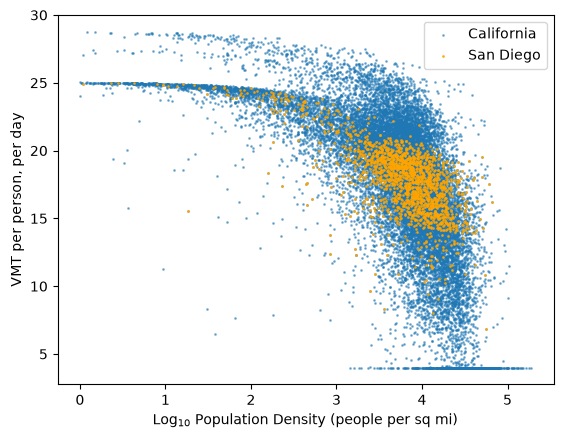

In [221]:
# Scatterplot
# First filter to rows with > 0 pop density. We'll use > 1 to avoid small floating point issues.
vmt_subset = vmt_merged[vmt_merged['Population Density'] > 1]

# Plot the statewide data
plt.scatter(np.log10(vmt_subset['Population Density']), vmt_subset['VMTpc'], s=1, alpha=0.5, label='California')

# San Diego data overlaid
sd_vmt_subset = vmt_subset[vmt_subset.index.str.startswith('06073')]
plt.scatter(np.log10(sd_vmt_subset['Population Density']), sd_vmt_subset['VMTpc'], s=1, color='orange', alpha=0.8, label='San Diego')

plt.ylabel('VMT per person, per day')
plt.xlabel('Log$_{10}$ Population Density (people per sq mi)')
plt.legend()


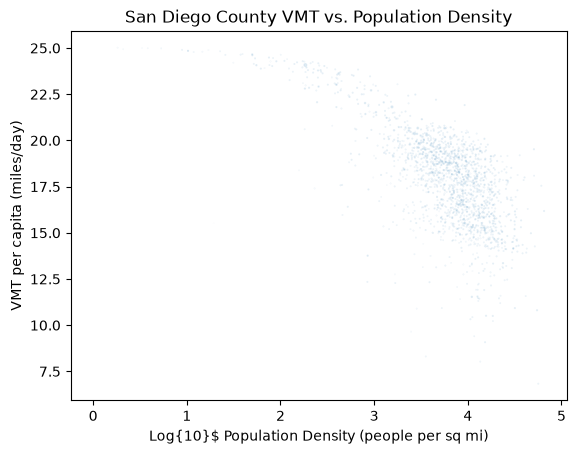

In [222]:
# Filter for San Diego County (state FIPS 06, county FIPS 073)
sd_vmt_merged = vmt_merged[vmt_merged.index.str.startswith('06073')]

plt.scatter(np.log10(sd_vmt_merged['Population Density'] + 1), sd_vmt_merged['VMTpc'], s=sd_vmt_merged['Population']/1e4, alpha=0.1)
plt.xlabel('Log{10}$ Population Density (people per sq mi)')
plt.ylabel('VMT per capita (miles/day)')
plt.title('San Diego County VMT vs. Population Density')
plt.show()


In [223]:
np.corrcoef(np.log10(vmt_subset['Population Density']), vmt_subset['VMTpc'])

array([[ 1.        , -0.63766904],
       [-0.63766904,  1.        ]])

In [224]:
len(sd_vmt)

1794

In [225]:
sd_vmt = sd_vmt.merge(pop, left_index=True, right_index=True, how='inner')
sd_vmt = sd_vmt.merge(housing_units,left_index=True, right_index=True, how='inner') 


In [226]:
sd_vmt.head()

,VMTpc,geometry,Population,Housing Units
GEOID,,,,
060730033051,15.308582,"POLYGON ((-117.09519 32.70412, -117.09492 32.7...",1087,225
060730083472,17.900582,"POLYGON ((-117.15141 32.92595, -117.15186 32.9...",1903,525
060730080063,17.273582,"POLYGON ((-117.26217 32.80799, -117.25928 32.8...",632,401
060730158011,15.260582,"POLYGON ((-116.96235 32.79911, -116.9581 32.79...",1834,803
060730116012,14.350582,"POLYGON ((-117.10356 32.6672, -117.09535 32.66...",1331,493


In [227]:
sd_popmean_vmt = (sd_vmt['VMTpc'] * sd_vmt['Population']).sum() / sd_vmt['Population'].sum()
sd_popmean_vmt

np.float64(18.167103324609975)

In [228]:
sd_popmean_vmt - statewide_mean_vmt_calc

np.float64(0.031531328105639744)

In [229]:
deciles = np.arange(0, 1.1, 0.1)
sd_vmt_deciles = np.quantile(sd_vmt['VMTpc'], deciles, weights=sd_vmt['Population'],
                            method='inverted_cdf')

# To make it easier to look at, let's make a dictionary using "Dictionary Comprehension" (e.g. https://www.geeksforgeeks.org/python/python-dictionary-comprehension/).
sd_vmt_deciles = {round(deciles[x], 1): round(sd_vmt_deciles[x], 1) for x in range(len(deciles))}
sd_vmt_deciles

{np.float64(0.0): np.float64(6.8),
 np.float64(0.1): np.float64(15.1),
 np.float64(0.2): np.float64(16.0),
 np.float64(0.3): np.float64(16.8),
 np.float64(0.4): np.float64(17.6),
 np.float64(0.5): np.float64(18.2),
 np.float64(0.6): np.float64(18.8),
 np.float64(0.7): np.float64(19.3),
 np.float64(0.8): np.float64(20.0),
 np.float64(0.9): np.float64(21.4),
 np.float64(1.0): np.float64(25.0)}

Below here is where Chris will try to add in San Diego (City) Data

# Economic Characteristics of San Diego County

From US Census Bureau DP03 (Economic Characteristics)
- 0004E (Total Employed)
- 0009PE Unemployment Rate
- 0062E Median Household Income
- 0119PE Percent of families below the poverty level
- 0019E Drove alone
- 0020E Carpooled
- 0021E Public Transportation (excludes rideshare)
- 0024E Worked from home
- 0025E Mean Travel time to work (in minutes)

In [ ]:
# target columns / when you download a ZIP file from the US census buereau, there is a file in there called -'column-metadata.csv' and that's how you can map the column "codes" to new column names so it's easiet to filter, etc
columns_to_keep = { # when you use {} it's called a 'dictionary' and you map key:value pairs to each other. If you download a new dataset, I recommend setting up a dictionary like this because it's very configurable and easy to add/remove new columns
    'GEO_ID': 'GEOID', 
    'DP03_0062E': 'Median_Income',
    'DP03_0128PE': 'Percent_Poverty_All_People',
    'DP03_0009PE': 'Unemployment_Rate',
    'DP03_0019E': 'Commute_Drove_Alone',
    'DP03_0020E': 'Commute_Carpooled',
    'DP03_0021E': 'Commute_Transit',
    'DP03_0024E': 'Commute_WFH',
    'DP03_0025E': 'Mean_Commute_Time_Mins'
}

# read file using the pandas .read_csv that points to where the data is stored (the inputdir is defined further up in the notebook)
df_dp03 = pd.read_csv(inputdir / 'DP03/ACSDP5Y2019.DP03-Data.csv', skiprows=[1], usecols=columns_to_keep.keys())

# rename col - this essentially says for the data frame (df) df_dp03 rename the columns using the dictionary we mapped above
df_dp03 = df_dp03.rename(columns=columns_to_keep)

# strip US from GEOID as done with VMT
df_dp03['GEOID'] = df_dp03['GEOID'].str.split('US').str[1]
df_dp03 = df_dp03.set_index('GEOID')

# if you change the number in the paranthesis it will show that number of rows in the dataframe. It defaults to 5 if you don't add a number.
df_dp03.head()


,Commute_Drove_Alone,Commute_Carpooled,Commute_Transit,Commute_WFH,Mean_Commute_Time_Mins,Median_Income,Unemployment_Rate,Percent_Poverty_All_People
GEOID,,,,,,,,
06073000100,1105,59,9,203,20.1,138879,2.8,2.1
06073000201,735,49,50,67,26.3,88125,3.6,12.5
06073000202,2032,101,182,266,21.7,76658,2.8,4.7
06073000300,2476,101,101,288,22.0,68679,3.7,12.5
06073000400,1741,64,341,214,25.3,70267,7.8,6.6


Plots for DP03

<Axes: >

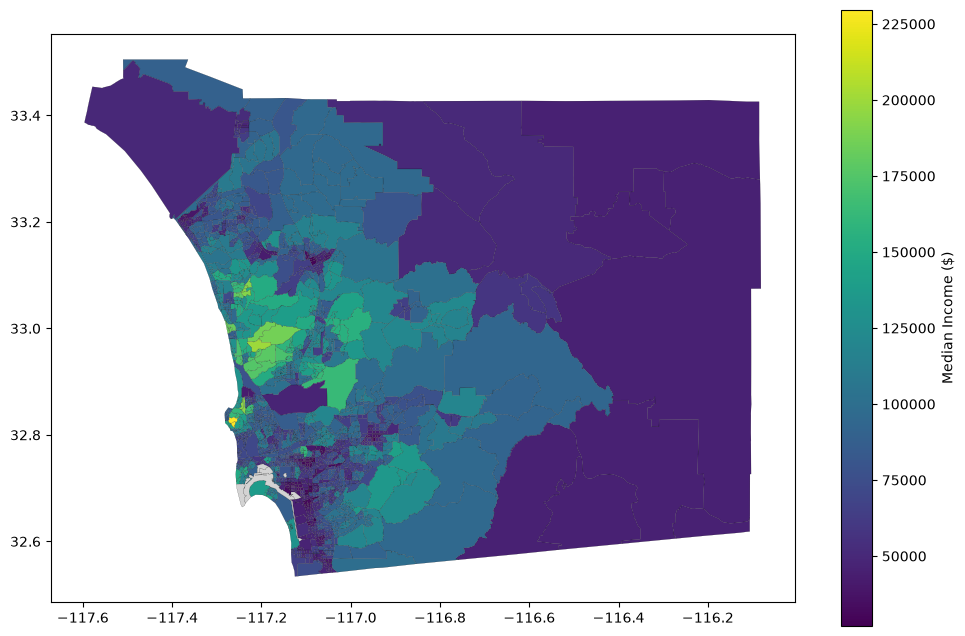

In [ ]:
sd_shape['Tract_GEOID'] = sd_shape['GEOID'].str[:11] # strips first 11 characters using some neat splicing

sd_demographics = sd_shape.merge(df_dp03, left_on='Tract_GEOID', right_index=True, how='inner') # this is merging two datasets, our dp03 dataframe with the demographics dataframe that has the GEOID data so we can plot it

sd_demographics['Median_Income'] = pd.to_numeric(sd_demographics['Median_Income'], errors='coerce') # this is to 'coerce' a text value to a numeric value so that you can perform calculations on it. Essentially just formatting a string to an integer.
sd_demographics.plot(
    column='Median_Income', # you can swap this variable out with any one of the "Columns to Keep" to update the chart below, or just copy this whole code block and create a brand new chart. Don't forget to also update where it says 'Median Income' in the coerce section.
    legend=True, 
    cmap='viridis', # stylistic choice
    figsize=(12, 8), # how big do you want the chart     
    edgecolor='black', # style choice for boundary
    linewidth=0.1, # thickness of the boundary line  
    missing_kwds={'color': 'lightgrey'}, # this handles any census blocks that don't have data, they will show up light grey (kwds is python for keywords)
    legend_kwds={'label': 'Median Income ($)'}
)

